# Cross-normalized DCCM: MUC2 Glycosylated vs Non-glycosylated


In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

output_dir = "/home/computer2/analysis_simulations/analysis/plots_crossnorm_dca"
os.makedirs(output_dir, exist_ok=True)
print("Output dir:", output_dir)

Output dir: /home/computer2/analysis_simulations/analysis/plots_crossnorm_dca


## Load Data

In [7]:
base = "/home/computer2/analysis_simulations/analysis/crossnorm_dca/"

dccm_glyc   = np.load(base + "dccm_glyc_crossnorm.npy")
dccm_noglyc = np.load(base + "dccm_noglyc_crossnorm.npy")
diff        = np.load(base + "dccm_diff_crossnorm.npy")

print(f"Glyc   shape: {dccm_glyc.shape}")
print(f"Noglyc shape: {dccm_noglyc.shape}")
print(f"Glyc   range: [{dccm_glyc.min():.4f}, {dccm_glyc.max():.4f}]")
print(f"Noglyc range: [{dccm_noglyc.min():.4f}, {dccm_noglyc.max():.4f}]")
print(f"Diff   range: [{diff.min():.4f},  {diff.max():.4f}]")

n_res  = dccm_glyc.shape[0]
v      = max(abs(dccm_glyc).max(), abs(dccm_noglyc).max())
v_diff = abs(diff).max()
print(f"\nShared scale: ±{v:.4f}  |  Diff scale: ±{v_diff:.4f}")

Glyc   shape: (2265, 2265)
Noglyc shape: (2265, 2265)
Glyc   range: [-1.1196, 1.8554]
Noglyc range: [-0.4307, 1.1348]
Diff   range: [-0.9428,  1.3164]

Shared scale: ±1.8554  |  Diff scale: ±1.3164


## Domain Boundaries

In [8]:
# Domain end boundaries (1-indexed, matching residue axis)
domains = [
    (367,  "D1"),
    (837,  "D2"),
    (1238, "D3"),
    (1278, "Short PTS"),
    (1376, "CYSD"),
    (1642, "Long PTS"),
    (n_res, "D4+CTCK"),
]

def add_domain_lines(ax):
    for end, name in domains:
        ax.axvline(end, color="black", linewidth=1.0, linestyle=(0, (4, 4)), alpha=0.9)
        ax.text(end, 1.005, name, ha="right", va="bottom",
                fontsize=6.5, color="black", rotation=0,
                transform=ax.get_xaxis_transform(), clip_on=False)

## Three-Panel Comparison

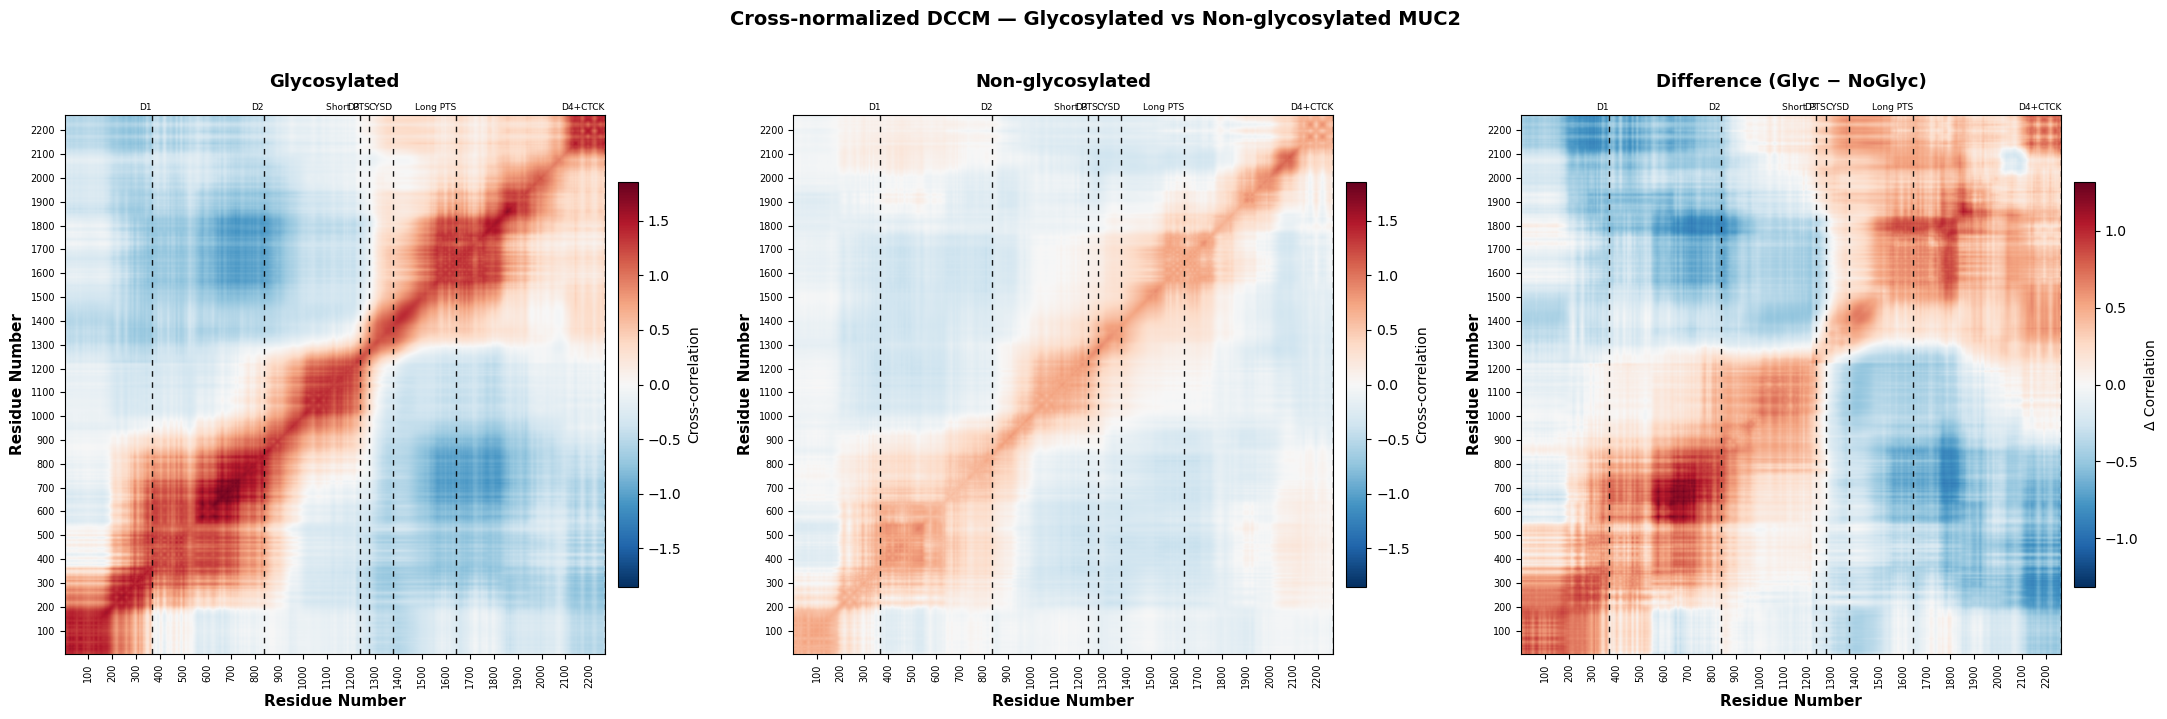

Saved: /home/computer2/analysis_simulations/analysis/plots_crossnorm_dca/dccm_three_panel.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(22, 7), dpi=800)

configs = [
    (axes[0], dccm_glyc,   "Glycosylated",              "RdBu_r",   -v,      v,      "Cross-correlation"),
    (axes[1], dccm_noglyc, "Non-glycosylated",           "RdBu_r",   -v,      v,      "Cross-correlation"),
    (axes[2], diff,        "Difference (Glyc \u2212 NoGlyc)", "RdBu_r", -v_diff, v_diff, "\u0394 Correlation"),
]

for ax, mat, title, cmap, lo, hi, cbar_label in configs:
    im = ax.imshow(mat, cmap=cmap, vmin=lo, vmax=hi,
                   origin="lower", aspect="auto",
                   extent=[1, n_res, 1, n_res])
    add_domain_lines(ax)
    ax.set_title(title, fontsize=13, fontweight="bold", pad=20)
    ax.set_xlabel("Residue Number", fontsize=11, fontweight="bold")
    ax.set_ylabel("Residue Number", fontsize=11, fontweight="bold")
    ax.xaxis.set_major_locator(ticker.MultipleLocator(100))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(100))
    ax.tick_params(axis="x", rotation=90, labelsize=7)
    ax.tick_params(axis="y", labelsize=7)
    plt.colorbar(im, ax=ax, shrink=0.75, pad=0.02, label=cbar_label)

plt.suptitle("Cross-normalized DCCM \u2014 Glycosylated vs Non-glycosylated MUC2",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
out = os.path.join(output_dir, "dccm_three_panel.png")
plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Individual Full-Size Plots

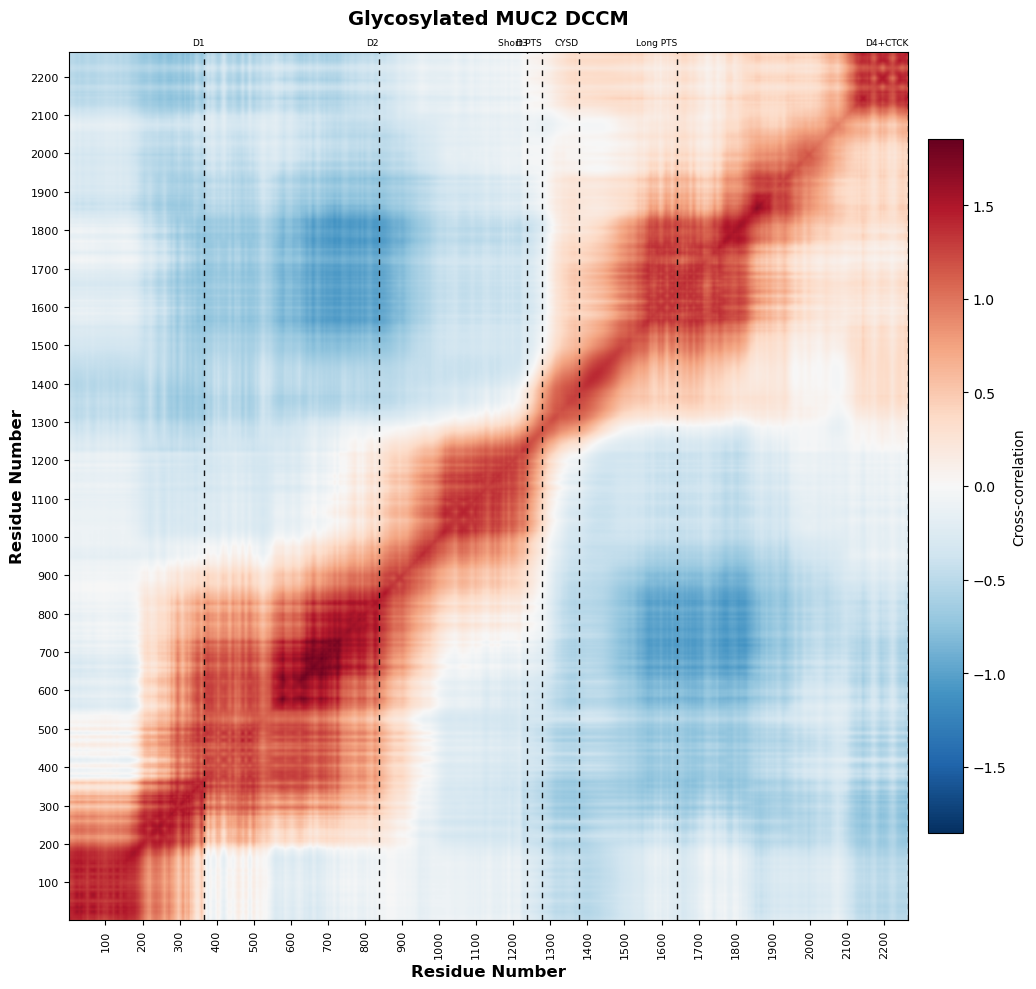

Saved: /home/computer2/analysis_simulations/analysis/plots_crossnorm_dca/dccm_glyc.png


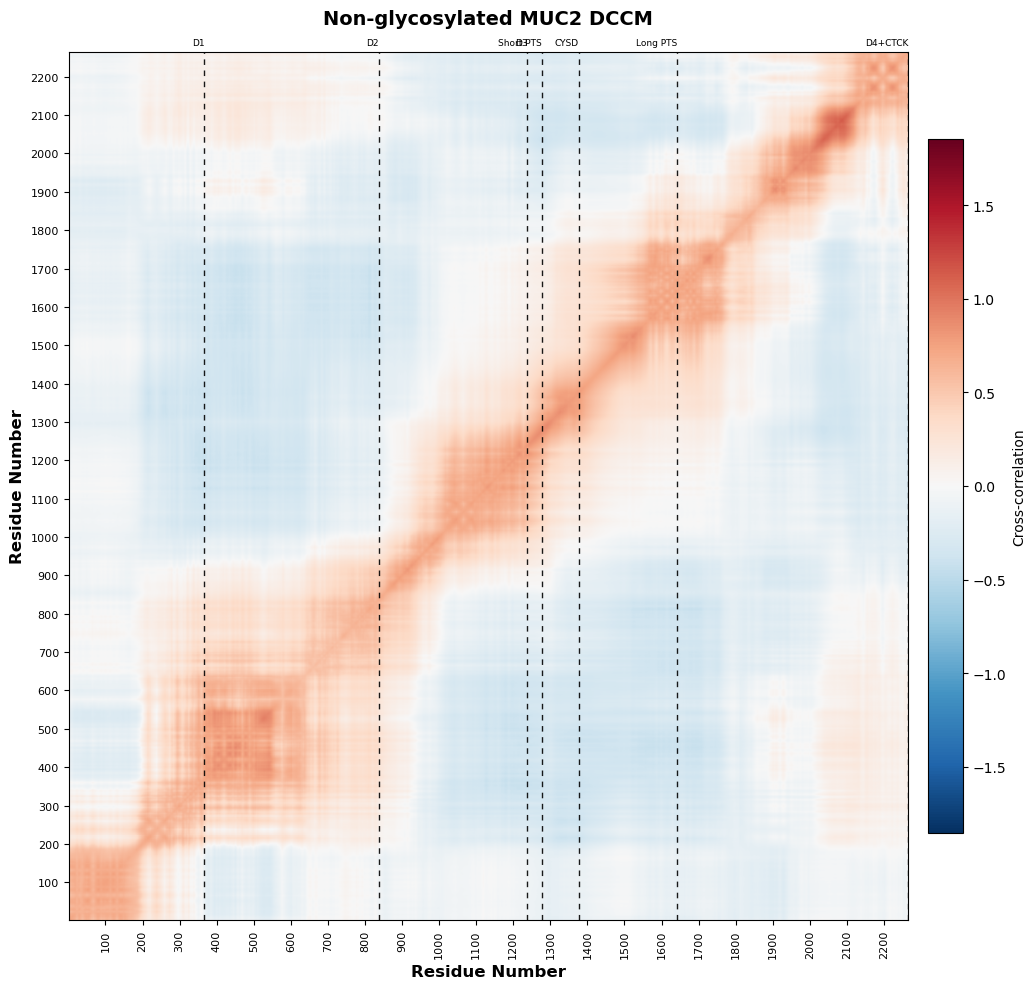

Saved: /home/computer2/analysis_simulations/analysis/plots_crossnorm_dca/dccm_noglyc.png


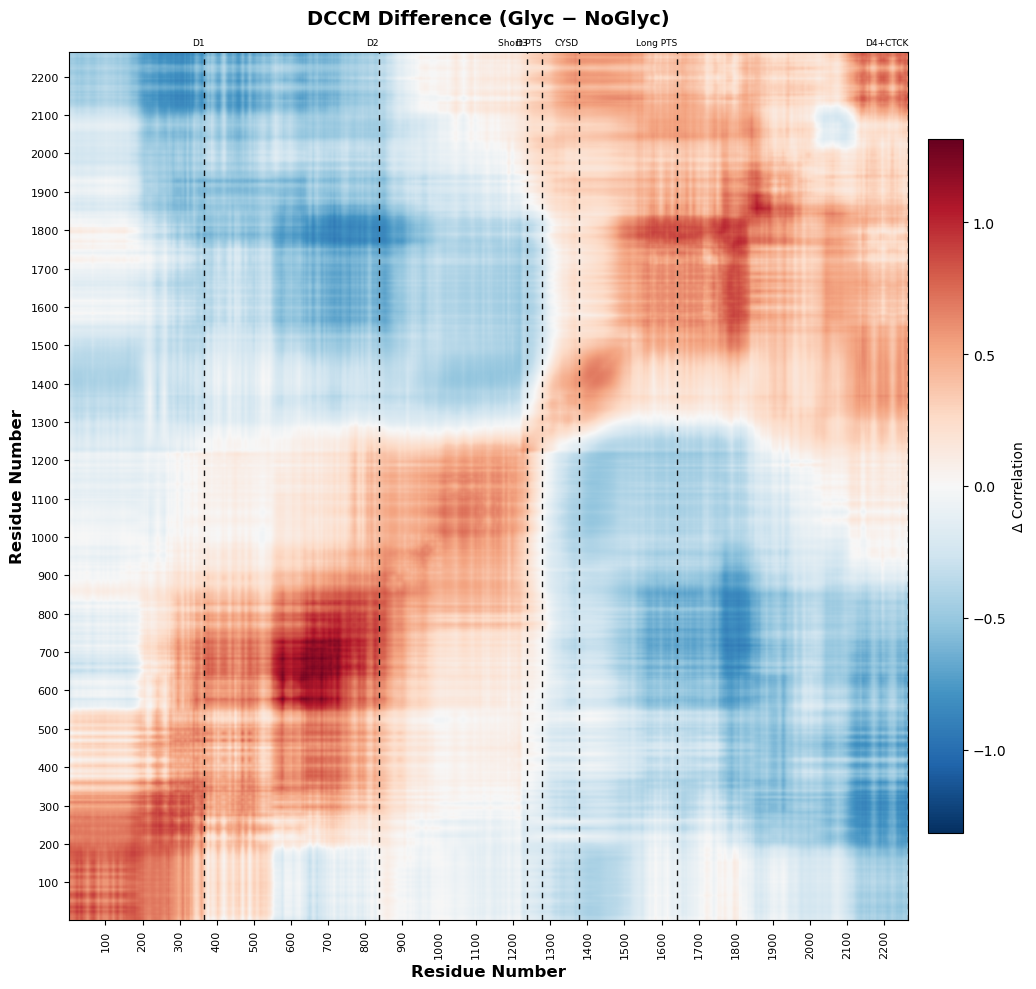

Saved: /home/computer2/analysis_simulations/analysis/plots_crossnorm_dca/dccm_diff.png


In [10]:
plots = [
    (dccm_glyc,   "Glycosylated MUC2 DCCM",          "dccm_glyc.png",   "RdBu_r",   -v,      v,      "Cross-correlation"),
    (dccm_noglyc, "Non-glycosylated MUC2 DCCM",       "dccm_noglyc.png", "RdBu_r",   -v,      v,      "Cross-correlation"),
    (diff,        "DCCM Difference (Glyc \u2212 NoGlyc)", "dccm_diff.png",   "RdBu_r",   -v_diff, v_diff, "\u0394 Correlation"),
]

for mat, title, fname, cmap, lo, hi, cbar_label in plots:
    fig, ax = plt.subplots(figsize=(11, 10), dpi=100)
    im = ax.imshow(mat, cmap=cmap, vmin=lo, vmax=hi,
                   origin="lower", aspect="auto",
                   extent=[1, n_res, 1, n_res])
    add_domain_lines(ax)
    ax.set_title(title, fontsize=14, fontweight="bold", pad=20)
    ax.set_xlabel("Residue Number", fontsize=12, fontweight="bold")
    ax.set_ylabel("Residue Number", fontsize=12, fontweight="bold")
    ax.xaxis.set_major_locator(ticker.MultipleLocator(100))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(100))
    ax.tick_params(axis="x", rotation=90, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)
    plt.colorbar(im, ax=ax, shrink=0.8, pad=0.02, label=cbar_label)
    plt.tight_layout()
    out = os.path.join(output_dir, fname)
    plt.savefig(out, dpi=800, bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"Saved: {out}")